# Delivery Time Prediction with Linear Regression

**Question:** how well can a linear model predict how long a food order takes to arrive, and which order and operating conditions drive delivery time?

**Data:** 175,777 orders from a food-delivery case study, stored as `data/porter_data_1.csv`. The file was supplied with a course and is not redistributed; see `data/README.md` for the expected location and columns.

**Approach**

1. **Prepare** – parse the timestamps, derive delivery duration (minutes), order hour, day of week and a weekend flag, and make an 80/20 train/test split (seed 42).
2. **Explore** – distributions, relationships and correlations, on the training set only.
3. **Clean** – drop weakly correlated features and remove outliers from the training set.
4. **Model** – standardise the numeric features, rank features with recursive feature elimination (RFE), and fit a linear regression on 8 features.
5. **Evaluate** – MAE, RMSE and R² on the held-out test set, and residual diagnostics.

The limitations of the analysis are collected in the final section and in `docs/findings.md`.

### Columns

| Column | Meaning |
| --- | --- |
| `market_id` | Market (area) the store belongs to, as an ID |
| `created_at` | When the order was placed |
| `actual_delivery_time` | When the order was delivered |
| `store_primary_category` | Store category, as a numeric code |
| `order_protocol` | How the order was placed, as a numeric code |
| `total_items` | Number of items in the order |
| `subtotal` | Order value |
| `num_distinct_items` | Number of distinct items in the order |
| `min_item_price`, `max_item_price` | Price of the cheapest and the most expensive item |
| `total_onshift_dashers` | Delivery partners on shift when the order was placed |
| `total_busy_dashers` | Delivery partners already busy with other orders |
| `total_outstanding_orders` | Orders pending fulfilment at that time |
| `distance` | Distance from the store to the customer (units are not stated in the source) |

## 0. Setup

In [ ]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# Paths work whether Jupyter is started in the repository root or in notebooks/.
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = REPO_ROOT / "data" / "porter_data_1.csv"

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_FEATURES = 8   # features kept by RFE in the final model

## 1. Load the data

In [ ]:
df = pd.read_csv(DATA_PATH)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 14 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   market_id                 175777 non-null  float64
 1   created_at                175777 non-null  object 
 2   actual_delivery_time      175777 non-null  object 
 3   store_primary_category    175777 non-null  int64  
 4   order_protocol            175777 non-null  float64
 5   total_items               175777 non-null  int64  
 6   subtotal                  175777 non-null  int64  
 7   num_distinct_items        175777 non-null  int64  
 8   min_item_price            175777 non-null  int64  
 9   max_item_price            175777 non-null  int64  
 10  total_onshift_dashers     175777 non-null  float64
 11  total_busy_dashers        175777 non-null  float64
 12  total_outstanding_orders  175777 non-null  float64
 13  distance                  175777 non-null  f

## 2. Preprocessing and feature engineering

### 2.1 Data types

The timestamps are read as text and are converted to datetimes. `market_id`, `store_primary_category` and `order_protocol` are identifiers rather than quantities, so they become categorical.

In [ ]:
# Convert 'created_at' and 'actual_delivery_time' columns to datetime format
df['created_at'] = pd.to_datetime(df['created_at'])
df['actual_delivery_time'] = pd.to_datetime(df['actual_delivery_time'])

In [ ]:
# Convert categorical features to category type
df['store_primary_category'] = df['store_primary_category'].astype('category')
df['order_protocol'] = df['order_protocol'].astype('category')
df['market_id'] = df['market_id'].astype('category')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 14 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   market_id                 175777 non-null  category      
 1   created_at                175777 non-null  datetime64[ns]
 2   actual_delivery_time      175777 non-null  datetime64[ns]
 3   store_primary_category    175777 non-null  category      
 4   order_protocol            175777 non-null  category      
 5   total_items               175777 non-null  int64         
 6   subtotal                  175777 non-null  int64         
 7   num_distinct_items        175777 non-null  int64         
 8   min_item_price            175777 non-null  int64         
 9   max_item_price            175777 non-null  int64         
 10  total_onshift_dashers     175777 non-null  float64       
 11  total_busy_dashers        175777 non-null  float64       
 12  to

### 2.2 Derived features

Delivery duration is the time between `created_at` and `actual_delivery_time`, in minutes. The order hour, the day of week (Monday = 0) and a weekend flag are taken from the order timestamp. The two raw timestamps are then dropped.

In [ ]:
# Calculate time taken in minutes
df['delivery_duration'] = (df['actual_delivery_time'] - df['created_at']) / pd.Timedelta(minutes=1)

In [ ]:
# Extract the hour and day of week from the 'created_at' timestamp
df['order_hour'] = df['created_at'].dt.hour
df['order_dayofweek'] = df['created_at'].dt.dayofweek 

# Create a categorical feature 'isWeekend'
df['isweekend'] = df['order_dayofweek'].isin([5, 6]).astype('category')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 18 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   market_id                 175777 non-null  category      
 1   created_at                175777 non-null  datetime64[ns]
 2   actual_delivery_time      175777 non-null  datetime64[ns]
 3   store_primary_category    175777 non-null  category      
 4   order_protocol            175777 non-null  category      
 5   total_items               175777 non-null  int64         
 6   subtotal                  175777 non-null  int64         
 7   num_distinct_items        175777 non-null  int64         
 8   min_item_price            175777 non-null  int64         
 9   max_item_price            175777 non-null  int64         
 10  total_onshift_dashers     175777 non-null  float64       
 11  total_busy_dashers        175777 non-null  float64       
 12  to

In [ ]:
# Drop unnecessary columns
df = df.drop(['created_at', 'actual_delivery_time'], axis=1)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 16 columns):
 #   Column                    Non-Null Count   Dtype   
---  ------                    --------------   -----   
 0   market_id                 175777 non-null  category
 1   store_primary_category    175777 non-null  category
 2   order_protocol            175777 non-null  category
 3   total_items               175777 non-null  int64   
 4   subtotal                  175777 non-null  int64   
 5   num_distinct_items        175777 non-null  int64   
 6   min_item_price            175777 non-null  int64   
 7   max_item_price            175777 non-null  int64   
 8   total_onshift_dashers     175777 non-null  float64 
 9   total_busy_dashers        175777 non-null  float64 
 10  total_outstanding_orders  175777 non-null  float64 
 11  distance                  175777 non-null  float64 
 12  delivery_duration         175777 non-null  float64 
 13  order_hour                175

### 2.3 Train/test split

The split is made before any exploration, so the outlier bounds and the scaling statistics used later come from the training set only.

In [ ]:
# Define target variable (y) and features (X)
y = df['delivery_duration']
X = df.drop('delivery_duration', axis=1)

In [ ]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

## 3. Exploratory analysis (training set)

### 3.1 Distributions

In [ ]:
# Define numerical and categorical columns for easy EDA and data manipulation
numerical_cols = X_train.select_dtypes(include=['int64', 'float64', 'int32']).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['category']).columns.tolist()

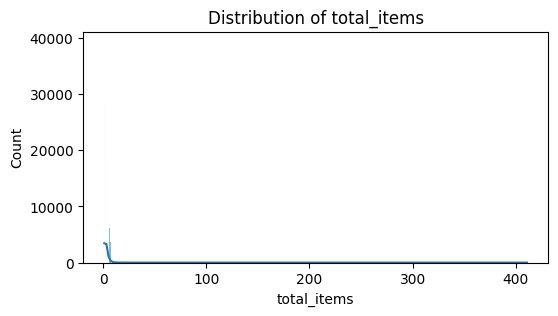

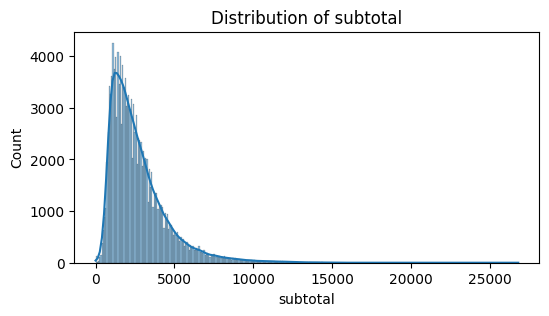

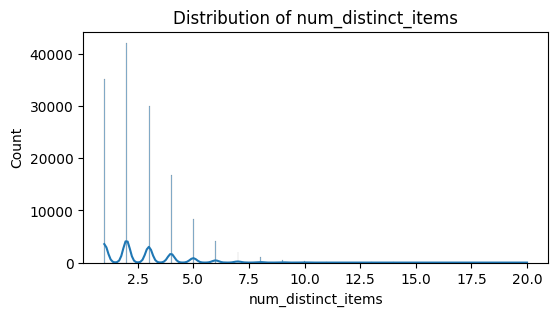

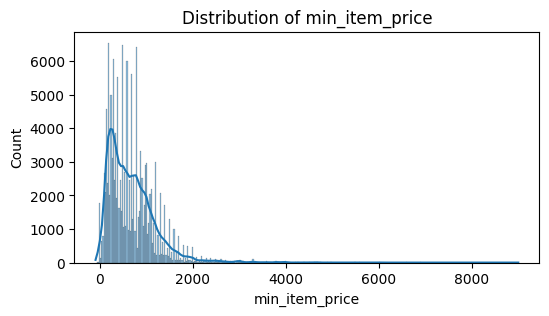

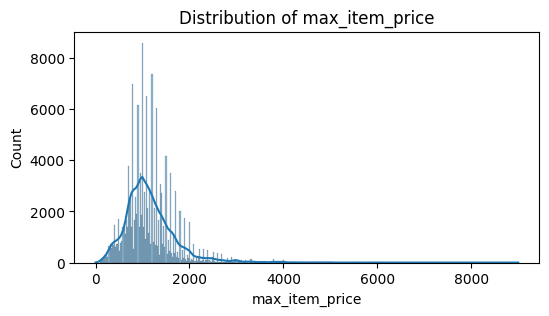

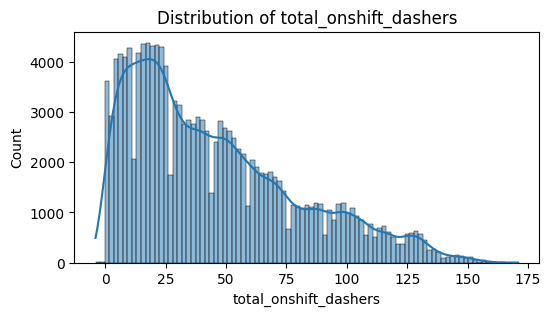

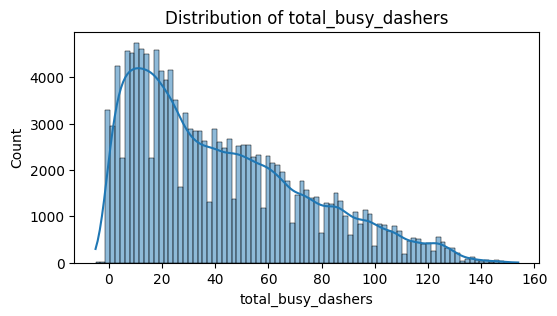

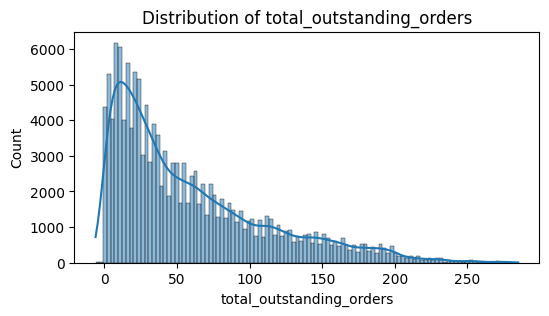

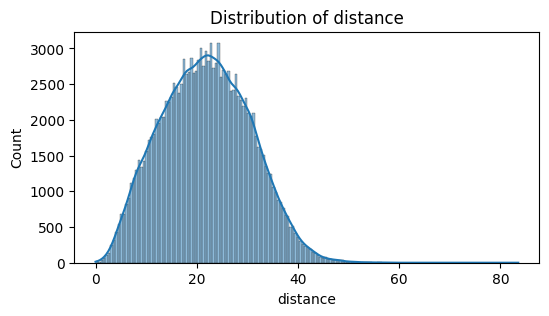

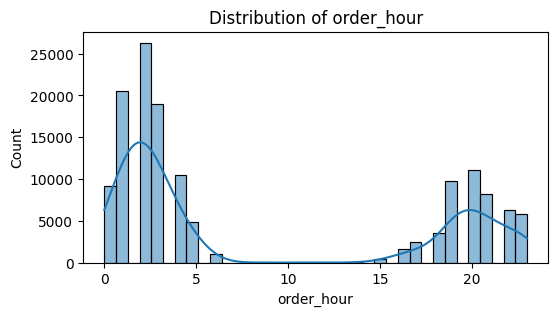

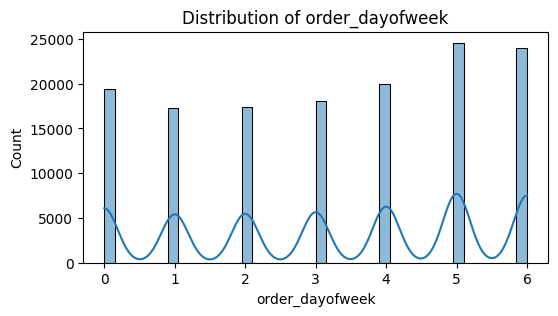

In [ ]:
# Plot distributions for all numerical columns
for col in numerical_cols:
    plt.figure(figsize=(6, 3))
    sns.histplot(X_train[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

- **Order hour is bimodal.** Most orders fall between midnight and 5 am, with the peak at 2 am, and between 7 pm and 11 pm. Orders in the hours 9 to 13 are absent, and 7, 8 and 14 are very sparse. The time zone of the timestamps is not stated, so these peaks cannot be tied to local meal times.
- **Day of week.** Saturday (5) and Sunday (6) have the most orders, roughly 24,000 each in the training set against roughly 17,000 to 20,000 on other days.
- **Skew.** Subtotal, item counts, item prices and the three dasher and order counts are right-skewed. Most orders contain one to a few items.

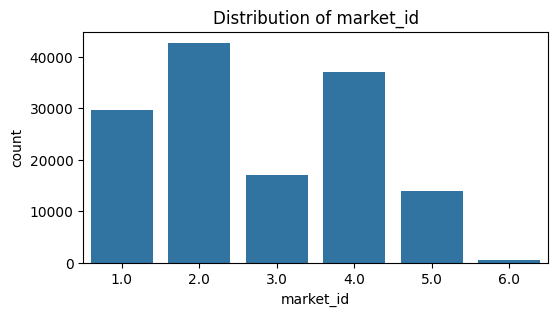

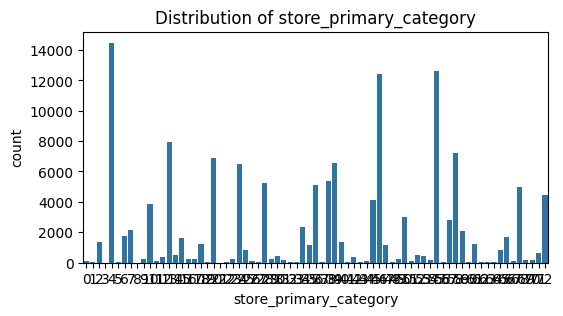

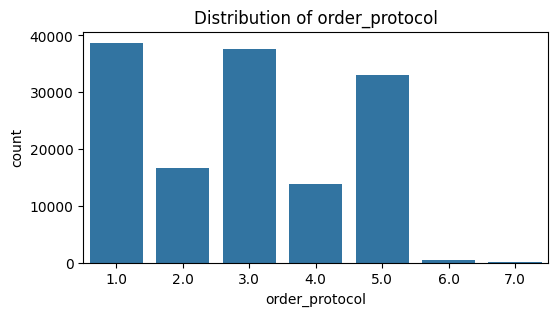

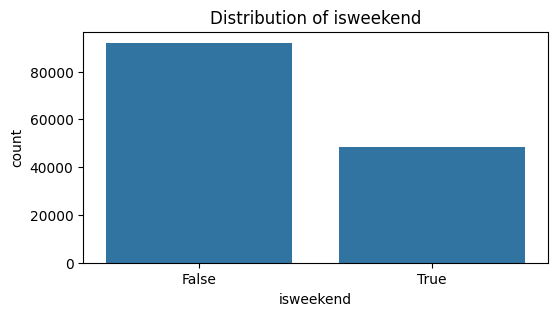

In [ ]:
# Distribution of categorical columns
for col in categorical_cols:
    plt.figure(figsize=(6, 3))
    sns.countplot(x=X_train[col])
    plt.title(f'Distribution of {col}')
    plt.show()

Weekday orders (`isweekend` = False) number roughly 92,000 against roughly 48,000 on weekends. That compares five days with two; per day, weekends carry about 24,000 orders against about 18,000 on a weekday.

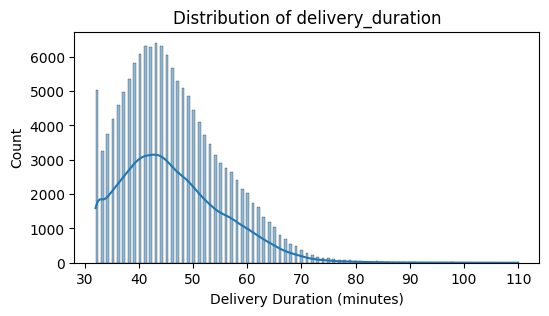

In [ ]:
# Distribution of time_taken
plt.figure(figsize=(6, 3))
sns.histplot(y_train, kde=True)
plt.title('Distribution of delivery_duration')
plt.xlabel('Delivery Duration (minutes)')
plt.show()

Delivery duration ranges from about 32 to about 110 minutes. It peaks near 43 minutes and has a long right tail; durations above 80 minutes are rare.

### 3.2 Relationships with delivery duration

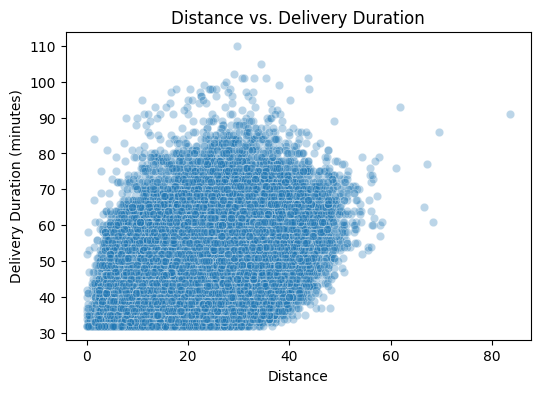

In [ ]:
# Scatter plot to visualise the relationship between time_taken and other features
plt.figure(figsize=(6, 4))
sns.scatterplot(x=X_train['distance'], y=y_train, alpha=0.3)
plt.title('Distance vs. Delivery Duration')
plt.xlabel('Distance')
plt.ylabel('Delivery Duration (minutes)')
plt.show()


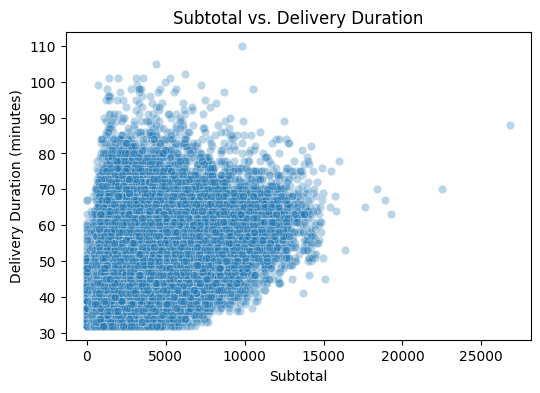

In [ ]:
plt.figure(figsize=(6, 4))
sns.scatterplot(x=X_train['subtotal'], y=y_train, alpha=0.3)
plt.title('Subtotal vs. Delivery Duration')
plt.xlabel('Subtotal')
plt.ylabel('Delivery Duration (minutes)')
plt.show()

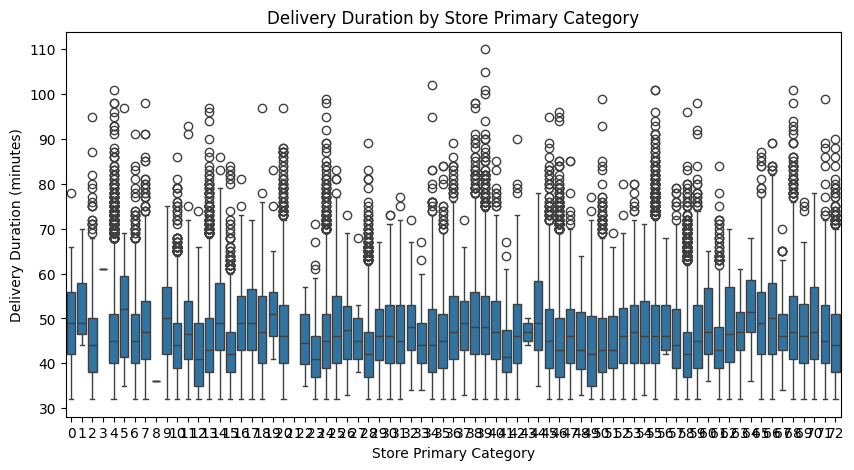

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=X_train['store_primary_category'], y=y_train)
plt.title('Delivery Duration by Store Primary Category')
plt.xlabel('Store Primary Category')
plt.ylabel('Delivery Duration (minutes)')
plt.show()

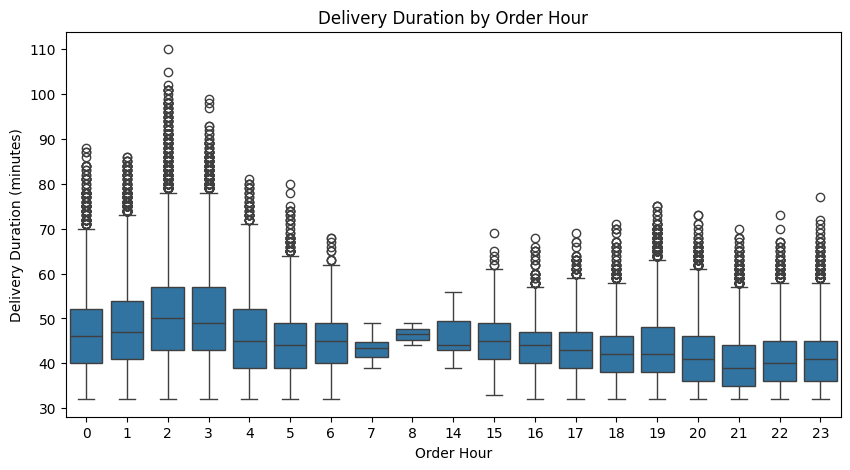

In [ ]:
# Show the distribution of time_taken for different hours
plt.figure(figsize=(10, 5))
sns.boxplot(x=X_train['order_hour'], y=y_train)
plt.title('Delivery Duration by Order Hour')
plt.xlabel('Order Hour')
plt.ylabel('Delivery Duration (minutes)')
plt.show()

- Duration rises with distance and with subtotal, with a wide scatter around the trend.
- The median duration is highest for orders placed at 2 and 3 am (about 49 to 50 minutes) and lowest from 8 pm to 11 pm (about 39 to 41 minutes). Orders at 2 and 3 am also have the longest upper tail.
- Store category shows no clear difference in median duration.

### 3.3 Correlations

In the heatmap the target is labelled `time_taken`; it is the delivery duration in minutes.

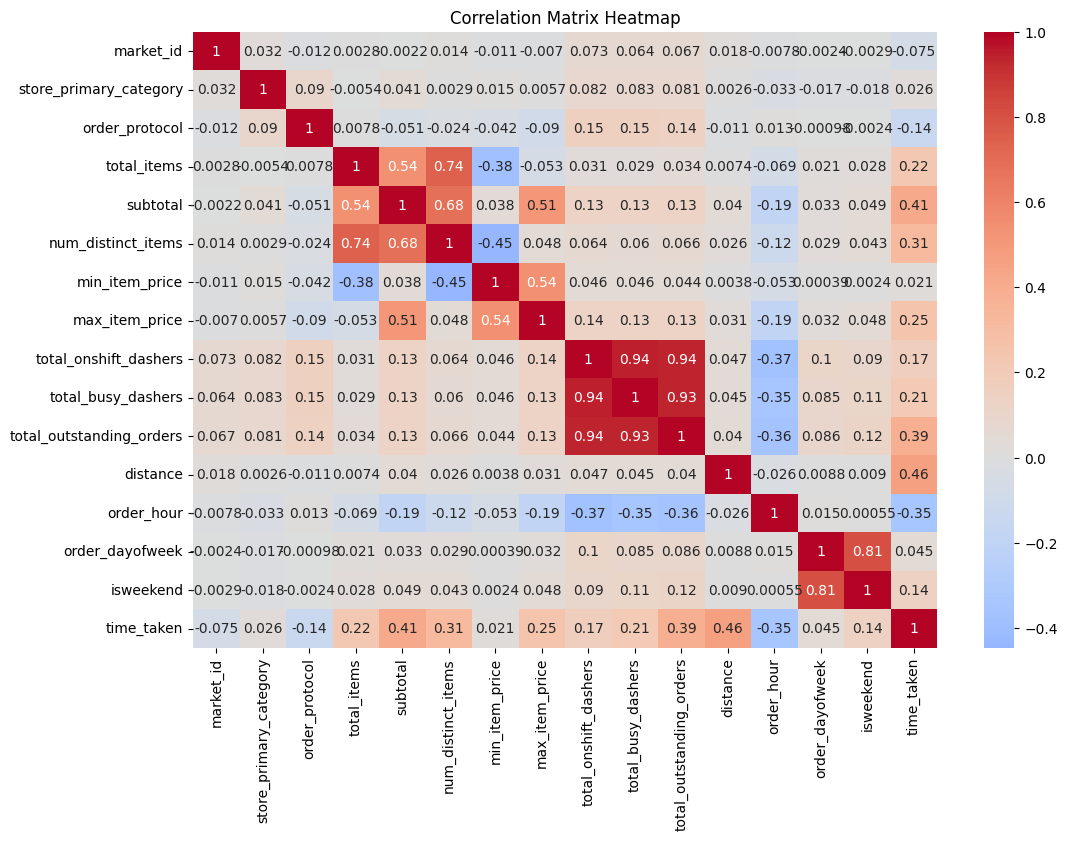

In [ ]:
# Plot the heatmap of the correlation matrix
train_corr = X_train.copy()
train_corr['time_taken'] = y_train

corr_matrix = train_corr.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix Heatmap')
plt.show()

Correlation with delivery duration: `distance` 0.46, `subtotal` 0.41, `total_outstanding_orders` 0.39, `order_hour` −0.35, `num_distinct_items` 0.31, `max_item_price` 0.25, `total_items` 0.22, `total_busy_dashers` 0.21, `total_onshift_dashers` 0.17, `order_protocol` −0.14, `isweekend` 0.14, `market_id` −0.08, `order_dayofweek` 0.05, `store_primary_category` 0.03 and `min_item_price` 0.02.

Two points matter for the model:

- `total_onshift_dashers`, `total_busy_dashers` and `total_outstanding_orders` correlate 0.93 to 0.94 with one another, so they carry largely the same information.
- Correlations for the coded identifiers (`market_id`, `order_protocol`, `store_primary_category`) depend on how the codes happen to be numbered and are only a rough guide.

The three columns with the weakest relationship to the target are dropped. `order_dayofweek` is also redundant with `isweekend` (correlation 0.81).

In [ ]:
# Drop 3-5 weakly correlated columns from training dataset
weak_corr_cols = ['min_item_price', 'store_primary_category', 'order_dayofweek']

X_train = X_train.drop(columns=weak_corr_cols)
X_test = X_test.drop(columns=weak_corr_cols)

### 3.4 Outliers

Boxplots show long right tails in the target and in most numeric features.

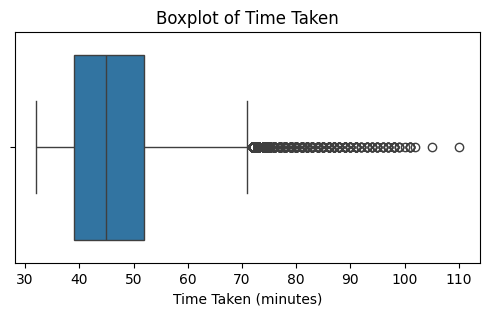

total_items


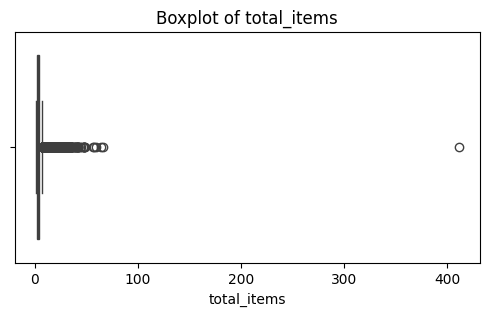

subtotal


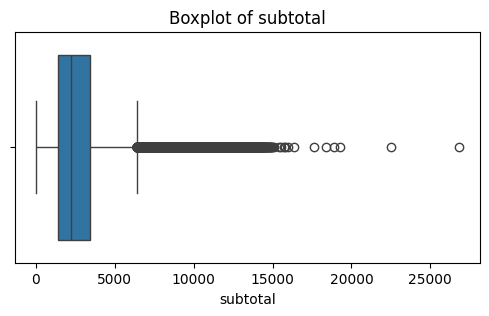

num_distinct_items


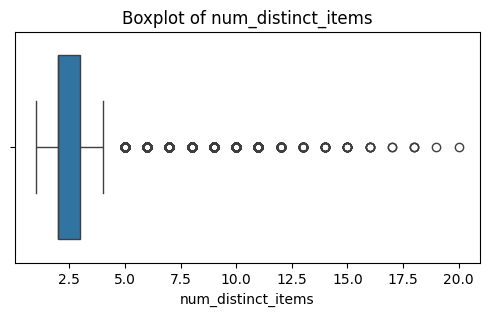

max_item_price


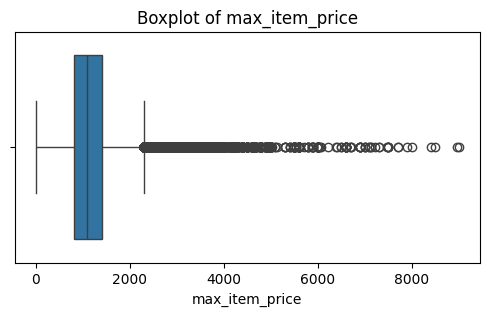

total_onshift_dashers


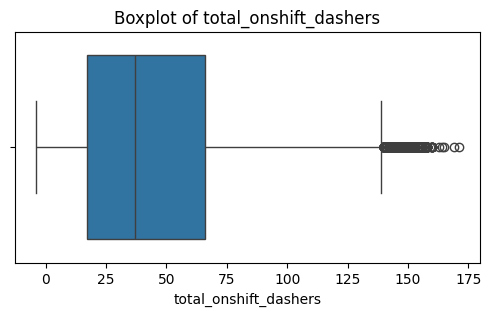

total_busy_dashers


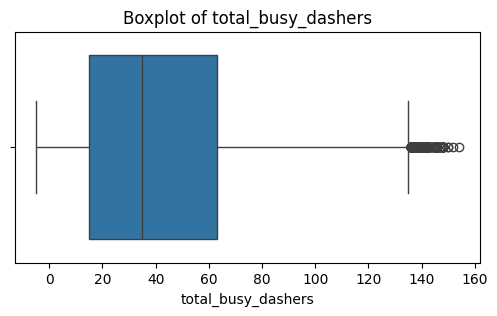

total_outstanding_orders


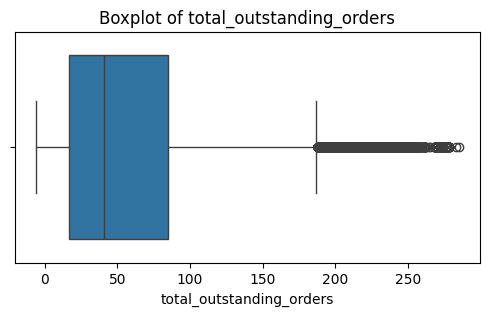

distance


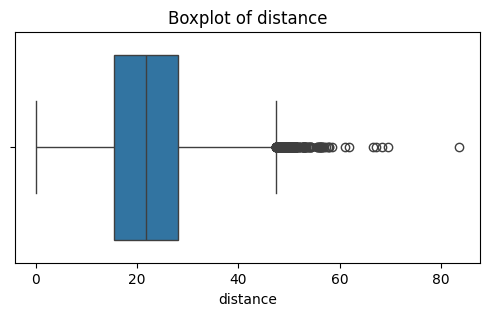

order_hour


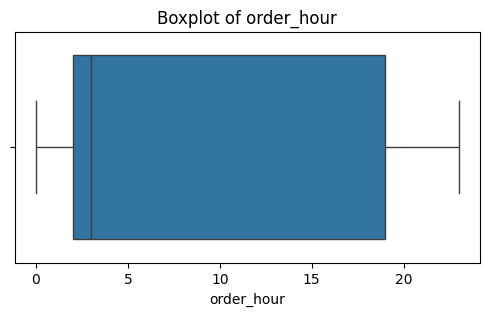

In [ ]:
# Boxplot for time_taken
plt.figure(figsize=(6, 3))
sns.boxplot(x=y_train)
plt.title('Boxplot of Time Taken')
plt.xlabel('Time Taken (minutes)')
plt.show()

# Boxplots for all numerical features in X_train
numerical_cols = X_train.select_dtypes(include=['int64', 'float64', 'int32']).columns.tolist()
for col in numerical_cols:
    print(col)
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=X_train[col])
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()

Outliers are removed from the **training set only**, using the 1.5 × IQR rule. The rule is applied column by column over every numeric column, including the target, with the quartiles recomputed after each column. Removal was chosen over capping or replacing values, which would shift the distribution towards the bound or the centre. The test set is left untouched so that evaluation reflects the raw data.

In [ ]:
# Handle outliers
def remove_outliers_iqr(df, cols):
    for col in cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df = df[(df[col] >= lower) & (df[col] <= upper)]
    return df

train_df = X_train.copy()
train_df['time_taken'] = y_train

cols_to_check = train_df.select_dtypes(include=['int64', 'float64', 'int32']).columns.tolist()
train_df_clean = remove_outliers_iqr(train_df, cols_to_check)

X_train_clean = train_df_clean.drop('time_taken', axis=1)
y_train_clean = train_df_clean['time_taken']

## 4. Model building

### 4.1 Feature scaling

Numeric features are standardised with statistics from the training set. Linear regression predicts the same values with or without scaling, and standardised inputs also keep RFE's feature ranking on a common scale. The categorical columns are left as they are.

In [ ]:
# Apply scaling to the numerical columns
numerical_cols = X_train_clean.select_dtypes(include=['int64', 'float64', 'int32']).columns.tolist()
scaler = StandardScaler()

X_train_scaled = X_train_clean.copy()
X_test_scaled = X_test.copy() 

X_train_scaled[numerical_cols] = scaler.fit_transform(X_train_clean[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test[numerical_cols])

### 4.2 How many features?

Recursive feature elimination (RFE) with a linear regression ranks the 12 remaining features. The loop below fits a model for every feature count from 1 to 12 and reports the MAE on the test set.

In [ ]:
# Loop through the number of features and test the model
results = []

for n_features in range(1, X_train_scaled.shape[1] + 1):
    lr = LinearRegression()
    selector = RFE(lr, n_features_to_select=n_features)
    selector.fit(X_train_scaled, y_train_clean)
    X_train_rfe = selector.transform(X_train_scaled)
    X_test_rfe = selector.transform(X_test_scaled)
    lr.fit(X_train_rfe, y_train_clean)
    y_pred = lr.predict(X_test_rfe)
    mae = mean_absolute_error(y_test, y_pred)
    results.append((n_features, mae))
    
for n, mae in results:
    print(f"Features: {n}, MAE: {mae:.2f}")

Features: 1, MAE: 6.91
Features: 2, MAE: 5.45
Features: 3, MAE: 4.25
Features: 4, MAE: 4.10
Features: 5, MAE: 3.15
Features: 6, MAE: 2.61
Features: 7, MAE: 2.53
Features: 8, MAE: 2.39
Features: 9, MAE: 2.36
Features: 10, MAE: 2.33
Features: 11, MAE: 2.32
Features: 12, MAE: 2.31


MAE falls steeply up to six features (6.91 → 2.61 minutes) and then flattens: 2.39 at eight features and 2.31 with all twelve. Eight features were kept as the point where further gains are small.

This choice was made by looking at test-set error, so the metrics below are slightly optimistic; selecting the feature count with cross-validation on the training set would avoid that.

### 4.3 Final model

In [ ]:
# Build the final model with selected number of features
optimal_features = 8
lr_final = LinearRegression()
selector_final = RFE(lr_final, n_features_to_select=optimal_features)
selector_final.fit(X_train_scaled, y_train_clean)

X_train_selected = selector_final.transform(X_train_scaled)
X_test_selected = selector_final.transform(X_test_scaled)

lr_final.fit(X_train_selected, y_train_clean)
y_pred_final = lr_final.predict(X_test_selected)

mae_final = mean_absolute_error(y_test, y_pred_final)
rmse_final = np.sqrt(mean_squared_error(y_test, y_pred_final))
r2_final = r2_score(y_test, y_pred_final)

print(f"MAE: {mae_final:.2f}")
print(f"RMSE: {rmse_final:.2f}")
print(f"R^2 Score: {r2_final:.2f}")

MAE: 2.39
RMSE: 3.39
R^2 Score: 0.87


On the held-out test set the final model has an **MAE of 2.39 minutes, an RMSE of 3.39 minutes and an R² of 0.87**.

## 5. Residual analysis

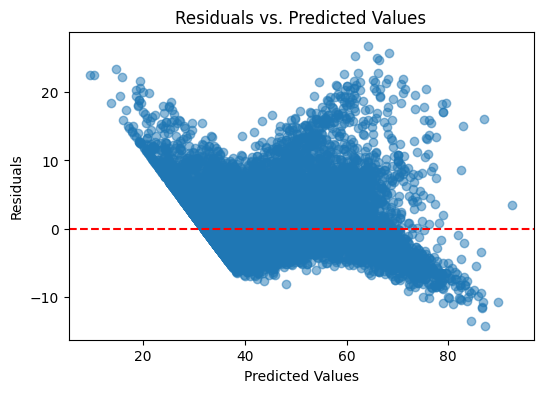

In [ ]:
# Perform residual analysis using plots like residuals vs predicted values, Q-Q plot and residual histogram
residuals = y_test - y_pred_final

plt.figure(figsize=(6,4))
plt.scatter(y_pred_final, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs. Predicted Values')
plt.show()

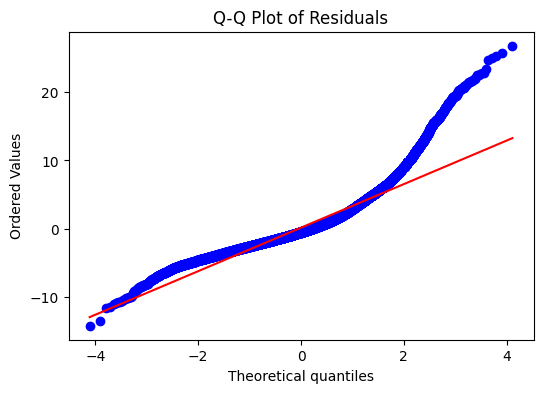

In [ ]:
plt.figure(figsize=(6,4))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title('Q-Q Plot of Residuals')
plt.show()

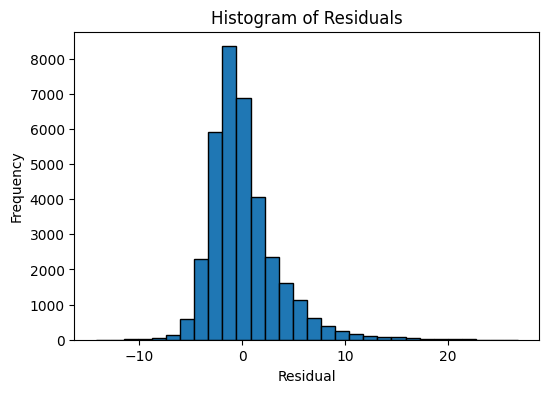

In [ ]:
plt.figure(figsize=(6,4))
plt.hist(residuals, bins=30, edgecolor='k')
plt.title('Histogram of Residuals')
plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.show()

- **Lower edge.** Residuals have a sharp diagonal lower boundary. This matches a floor of about 32 minutes in actual delivery times: an order predicted at 45 minutes cannot be delivered much faster than 32.
- **Right skew.** Long deliveries are under-predicted. Positive residuals reach about +25 minutes, while negative residuals stop near −14. The histogram is right-skewed and the Q-Q plot leaves the line in the upper tail, so the errors are not normally distributed.
- **Spread.** The scatter is wider at higher predicted values, so the model is least reliable for orders that take long.

## 6. Conclusions and limitations

**Conclusions**

- A linear model on 8 features predicts delivery time on held-out orders with an MAE of 2.39 minutes and an R² of 0.87.
- Distance is the strongest single correlate of delivery duration (0.46), followed by subtotal (0.41), outstanding orders (0.39) and order hour (−0.35).
- Orders placed at 2 and 3 am take longest, with a median of about 49 to 50 minutes.
- Delivery-capacity measures (partners on shift, partners busy, outstanding orders) move together, so the model cannot separate their individual effects.
- Errors are largest for long deliveries, which the model under-predicts.

**Limitations**

1. The number of features (8) was chosen on test-set error, so the reported metrics are slightly optimistic.
2. Results come from a single random split, without cross-validation.
3. `market_id`, `order_protocol` and the weekend flag enter the model as numbers; the identifiers are not one-hot encoded, and store category was dropped.
4. The three capacity features are highly collinear, so their individual effects cannot be separated.
5. Outliers were removed from the training set only. The model is fitted to typical orders and is weaker on long deliveries.
6. The time zone of the timestamps is not stated, and the training set has no orders for hours 9 to 13.
7. The units of `distance` are not stated.
8. Linear regression is the only model tried, and the residuals show non-normal, right-skewed errors.